# Exploration des donnees Instacart

Ce notebook commence l'EDA (analyse exploratoire) apres le nettoyage. Il etudie les habitudes de commande, les tailles de paniers et les rachats pour preparer les questions du cahier des charges : profils clients, associations de produits et prediction de rachat.

Il ne construit pas encore de modele de clustering ni de classification. Les interpretations devront etre verifiees avant de devenir des recommandations metier.

## 1. Prerequis et donnees

Executer d'abord `notebook/nettoyage_donnees.ipynb`. Ce notebook lit les copies nettoyees dans `data/processed/`, sans charger le fichier `prior` entierement.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

candidats = [Path.cwd(), *Path.cwd().parents]
PROJET = next((p for p in candidats if (p / "data" / "raw").is_dir()), None)
if PROJET is None:
    raise FileNotFoundError("Racine du projet introuvable : data/raw est absent.")

DOSSIER_PREPARE = PROJET / "data" / "processed"
FICHIERS = [
    "aisles.csv", "departments.csv", "orders.csv",
    "order_products__prior.csv", "order_products__train.csv", "products.csv",
]
fichiers_absents = [nom for nom in FICHIERS if not (DOSSIER_PREPARE / nom).is_file()]
if fichiers_absents:
    raise FileNotFoundError(
        "Copies preparees introuvables. Executer d'abord notebook/nettoyage_donnees.ipynb. "
        f"Fichiers absents : {fichiers_absents}"
    )

TAILLE_MORCEAU = 500_000
sns.set_theme(style="whitegrid")
print(f"Projet : {PROJET}")
print(f"Analyse des copies preparees : {DOSSIER_PREPARE}")

Projet : c:\Users\mouft\Desktop\data\data_m2
Analyse des copies preparees : c:\Users\mouft\Desktop\data\data_m2\data\processed


## 2. Combien de commandes et de clients ?

On parcourt `orders.csv` par blocs. Le nombre maximal de commandes numerotees pour un client donne son historique observe. Les jours sont gardes sous forme de codes 0 a 6, sans leur attribuer un nom de jour.

In [2]:
# Agregations qui tiennent en memoire : quelques compteurs et un maximum par client.
compte_jours = pd.Series(0, index=range(7), dtype="int64")
compte_heures = pd.Series(0, index=range(24), dtype="int64")
compte_eval = pd.Series(dtype="int64")
max_commandes_par_client = []
nombre_commandes = 0
valeurs_manquantes_delai = 0

for morceau in pd.read_csv(
    DOSSIER_PREPARE / "orders.csv",
    usecols=["user_id", "eval_set", "order_number", "order_dow", "order_hour_of_day", "days_since_prior_order"],
    chunksize=TAILLE_MORCEAU,
):
    nombre_commandes += len(morceau)
    compte_jours = compte_jours.add(morceau["order_dow"].value_counts(), fill_value=0).astype("int64")
    compte_heures = compte_heures.add(morceau["order_hour_of_day"].value_counts(), fill_value=0).astype("int64")
    compte_eval = compte_eval.add(morceau["eval_set"].value_counts(), fill_value=0).astype("int64")
    max_commandes_par_client.append(
        morceau.groupby("user_id")["order_number"].max()
    )
    valeurs_manquantes_delai += int(morceau["days_since_prior_order"].isna().sum())

commandes_client = (
    pd.concat(max_commandes_par_client)
    .groupby(level=0)
    .max()
    .rename("nombre_commandes")
)
resume_commandes = pd.DataFrame({
    "indicateur": ["Commandes", "Clients distincts", "Delais manquants"],
    "valeur": [nombre_commandes, len(commandes_client), valeurs_manquantes_delai],
})
display(resume_commandes)
print("Repartition des commandes :")
display(compte_eval.rename_axis("eval_set").to_frame("nombre"))

,indicateur,valeur
0,Commandes,3421083
1,Clients distincts,206209
2,Delais manquants,206209


Repartition des commandes :


,nombre
eval_set,
prior,3214874
test,75000
train,131209


## 3. Quand les clients commandent-ils ?

Ces graphiques decrivent le volume des commandes par code de jour et par heure. Ils montrent des tendances globales, pas les causes du comportement d'achat.

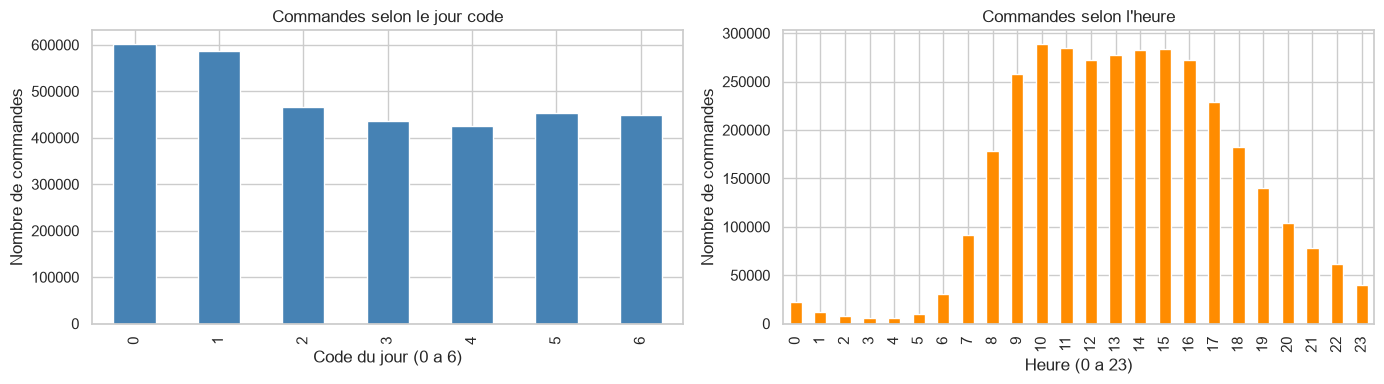

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
compte_jours.reindex(range(7), fill_value=0).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set(title="Commandes selon le jour code", xlabel="Code du jour (0 a 6)", ylabel="Nombre de commandes")
compte_heures.reindex(range(24), fill_value=0).plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set(title="Commandes selon l'heure", xlabel="Heure (0 a 23)", ylabel="Nombre de commandes")
plt.tight_layout()

Resume du nombre de commandes par client :


,statistique
count,206209.000000
mean,16.590367
std,16.654774
min,4.000000
25%,6.000000
50%,10.000000
75%,20.000000
max,100.000000


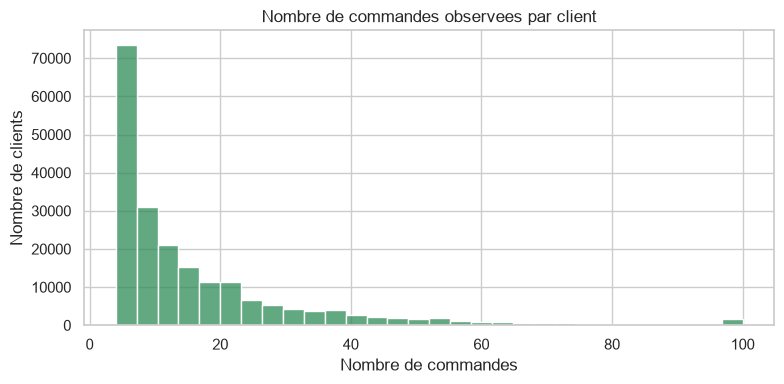

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(commandes_client, bins=30, color="seagreen")
plt.title("Nombre de commandes observees par client")
plt.xlabel("Nombre de commandes")
plt.ylabel("Nombre de clients")
plt.tight_layout()
print("Resume du nombre de commandes par client :")
display(commandes_client.describe().to_frame("statistique"))

## 4. Quelle est la taille des paniers et quelle part des lignes est un rachat ?

Le calcul est fait separement pour `prior` et `train`. L'ordre des commandes est verifie car le fichier est lu par morceaux ; cela permet de traiter correctement un panier qui se trouverait a la limite de deux morceaux.

In [3]:
def analyser_lignes_commandes(nom_fichier):
    """Calcule tailles de paniers et statistiques produits par morceaux."""
    morceaux_produits = []
    morceaux_paniers = []
    derniere_commande = None
    taille_derniere_commande = 0
    dernier_id_du_fichier = None
    nombre_lignes = 0

    chemin = DOSSIER_PREPARE / nom_fichier
    for numero_morceau, morceau in enumerate(pd.read_csv(
        chemin,
        usecols=["order_id", "product_id", "reordered"],
        chunksize=TAILLE_MORCEAU,
    )):
        nombre_lignes += len(morceau)
        ids_commandes = morceau["order_id"].to_numpy()
        if not morceau["order_id"].is_monotonic_increasing:
            raise ValueError(f"{nom_fichier} n'est pas trie par order_id.")
        if dernier_id_du_fichier is not None and ids_commandes[0] < dernier_id_du_fichier:
            raise ValueError(f"{nom_fichier} n'est pas trie entre les morceaux.")
        dernier_id_du_fichier = int(ids_commandes[-1])

        morceaux_produits.append(
            morceau.groupby("product_id")["reordered"].agg(
                nombre_lignes="size", nombre_rachats="sum"
            )
        )

        comptes = morceau.groupby("order_id", sort=False).size()
        ids = comptes.index.to_numpy()
        tailles = comptes.to_numpy(dtype=np.int64)

        if derniere_commande is not None:
            if ids[0] == derniere_commande:
                taille_derniere_commande += int(tailles[0])
                ids = ids[1:]
                tailles = tailles[1:]
                if len(tailles):
                    morceaux_paniers.append(np.array([taille_derniere_commande], dtype=np.uint16))
                    derniere_commande = None
                    taille_derniere_commande = 0
            else:
                morceaux_paniers.append(np.array([taille_derniere_commande], dtype=np.uint16))
                derniere_commande = None
                taille_derniere_commande = 0

        if len(tailles):
            if len(tailles) > 1:
                morceaux_paniers.append(tailles[:-1].astype(np.uint16))
            derniere_commande = int(ids[-1])
            taille_derniere_commande = int(tailles[-1])

        if (numero_morceau + 1) % 10 == 0:
            print(f"{nom_fichier} : {nombre_lignes:,} lignes lues...")

    if derniere_commande is not None:
        morceaux_paniers.append(np.array([taille_derniere_commande], dtype=np.uint16))

    paniers = np.concatenate(morceaux_paniers)
    produits = (
        pd.concat(morceaux_produits)
        .groupby(level=0)
        .sum()
        .reset_index()
    )
    produits["taux_rachat"] = produits["nombre_rachats"] / produits["nombre_lignes"]
    return paniers, produits

In [4]:
paniers_prior, produits_prior = analyser_lignes_commandes("order_products__prior.csv")
paniers_train, produits_train = analyser_lignes_commandes("order_products__train.csv")

resume_paniers = pd.DataFrame({
    "prior": pd.Series(paniers_prior).describe(),
    "train": pd.Series(paniers_train).describe(),
})
display(resume_paniers)

resume_rachats = pd.DataFrame({
    "jeu": ["prior", "train"],
    "lignes_produits": [int(produits_prior["nombre_lignes"].sum()), int(produits_train["nombre_lignes"].sum())],
    "taux_rachat": [produits_prior["nombre_rachats"].sum() / produits_prior["nombre_lignes"].sum(), produits_train["nombre_rachats"].sum() / produits_train["nombre_lignes"].sum()],
})
display(resume_rachats)

order_products__prior.csv : 5,000,000 lignes lues...
order_products__prior.csv : 10,000,000 lignes lues...
order_products__prior.csv : 15,000,000 lignes lues...
order_products__prior.csv : 20,000,000 lignes lues...
order_products__prior.csv : 25,000,000 lignes lues...
order_products__prior.csv : 30,000,000 lignes lues...


,prior,train
count,3.214874e+06,131209.000000
mean,1.008888e+01,10.552759
std,7.525398e+00,7.932847
min,1.000000e+00,1.000000
25%,5.000000e+00,5.000000
50%,8.000000e+00,9.000000
75%,1.400000e+01,14.000000
max,1.450000e+02,80.000000


,jeu,lignes_produits,taux_rachat
0,prior,32434489,0.589697
1,train,1384617,0.598594


## 5. Quels produits et rayons sont les plus presents ?

Les lignes de commande sont agregees par produit, puis reliees aux libelles de produits et de departements. Le taux de rachat par rayon est calcule comme une proportion ponderee des lignes, et non comme la moyenne des taux de chaque produit.

,department,nombre_lignes,nombre_rachats,taux_rachat
0,produce,9479291,6160710,0.649913
1,dairy eggs,5414016,3627221,0.669969
2,snacks,2887550,1657973,0.574180
3,beverages,2690129,1757892,0.653460
4,frozen,2236432,1211890,0.541885
5,pantry,1875577,650301,0.346721
6,bakery,1176787,739188,0.628141
7,canned goods,1068058,488535,0.457405
8,deli,1051249,638864,0.607719
9,dry goods pasta,866627,399581,0.461076


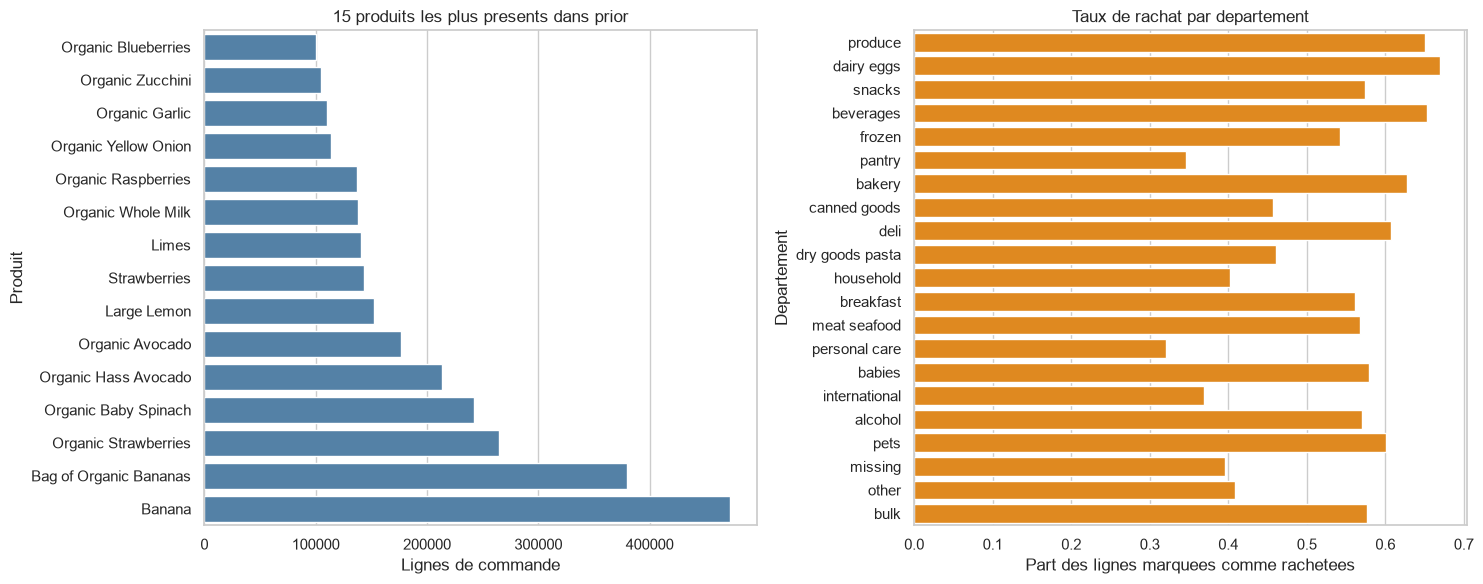

In [5]:
produits = pd.read_csv(DOSSIER_PREPARE / "products.csv")
departements = pd.read_csv(DOSSIER_PREPARE / "departments.csv")

catalogue = produits.merge(departements, on="department_id", how="left")
statistiques_produits = produits_prior.merge(catalogue, on="product_id", how="left")
statistiques_rayons = (
    statistiques_produits.groupby("department", dropna=False)
    .agg(nombre_lignes=("nombre_lignes", "sum"), nombre_rachats=("nombre_rachats", "sum"))
    .sort_values("nombre_lignes", ascending=False)
)
statistiques_rayons["taux_rachat"] = statistiques_rayons["nombre_rachats"] / statistiques_rayons["nombre_lignes"]

top_produits = statistiques_produits.nlargest(15, "nombre_lignes").sort_values("nombre_lignes")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=top_produits, x="nombre_lignes", y="product_name", ax=axes[0], color="steelblue")
axes[0].set(title="15 produits les plus presents dans prior", xlabel="Lignes de commande", ylabel="Produit")
sns.barplot(data=statistiques_rayons.reset_index(), x="taux_rachat", y="department", ax=axes[1], color="darkorange")
axes[1].set(title="Taux de rachat par departement", xlabel="Part des lignes marquees comme rachetees", ylabel="Departement")
plt.tight_layout()
display(statistiques_rayons.reset_index().head(10))

## 6. Reponses provisoires et limites

Utiliser les resultats et graphiques ci-dessus pour repondre avec des chiffres :

1. Les clients ont-ils des historiques de longueur tres differente ?
2. Quels codes de jour et quelles heures concentrent le plus de commandes ?
3. Quelle est la taille typique d'un panier, et quelle proportion des lignes est un rachat ?
4. Quels produits et departements dominent les commandes ?

Ces constats ne prouvent pas qu'un produit cause l'achat d'un autre. Les regles d'association sont explorees dans `notebook/associations/regles_association.ipynb`, avec support, confiance et lift. Une segmentation et une prediction necessiteront ensuite des variables, un protocole d'evaluation et des validations explicites.